In [1]:
import mplfinance as mpf
import pandas as pd
import yfinance as yf

### Candles

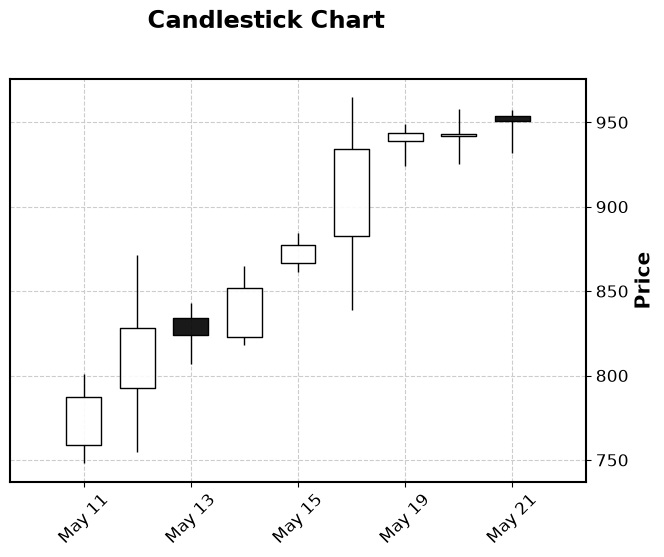

In [5]:
ticker = "BBOX.NS"
data = yf.Ticker(ticker).history(start="2026-05-10", end="2026-05-22")
df = pd.DataFrame(data).dropna()
mpf.plot(df, type='candle', style='classic', title='Candlestick Chart')

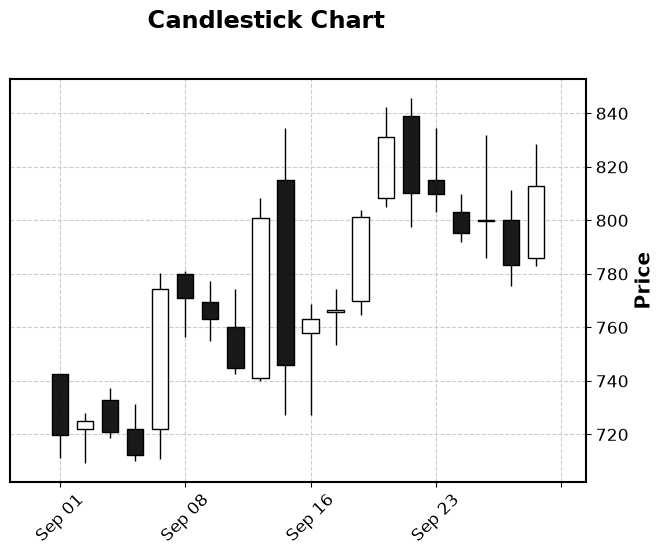

In [6]:
data = yf.Ticker(ticker).history(start="2026-09-01", end="2026-09-30")
df = pd.DataFrame(data).dropna()
mpf.plot(df, type='candle', style='classic', title='Candlestick Chart')

In [272]:
data = yf.Ticker("JIOFIN.NS").history(start="2026-08-01", end="2026-09-01")

In [273]:
len(data)

21

### Moving Averages - SMA

In [274]:
import matplotlib.pyplot as plt

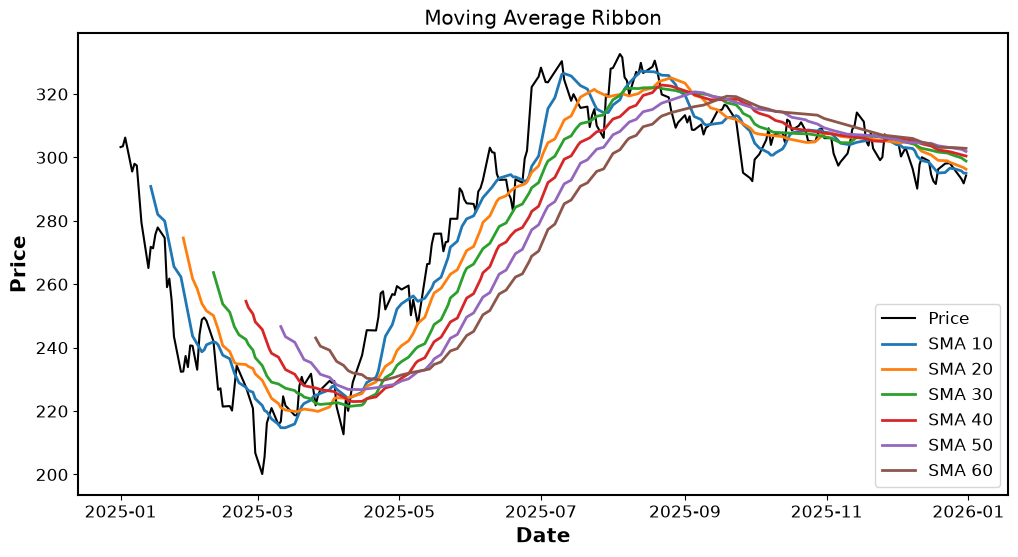

In [275]:
ticker = "JIOFIN.NS"
df = yf.Ticker(ticker).history(start="2025-01-1", end="2026-01-1")
df.reset_index(inplace=True)

# Define moving average periods for the ribbon
periods = [10, 20, 30, 40, 50, 60]
for period in periods:
    df[f"SMA_{period}"] = df["Close"].rolling(
        window=period).mean()

# Plot Moving Average Ribbon
plt.figure(figsize=(12, 6))
plt.plot(df["Date"], df["Close"], label="Price", color="black", linewidth=1.5)
for period in periods:
    plt.plot(df["Date"], df[f"SMA_{period}"], label=f"SMA {period}")
plt.title("Moving Average Ribbon")
plt.xlabel("Date")
plt.ylabel("Price")
plt.legend()
plt.grid()
plt.show()

In [43]:
ticker = "HCLTECH.NS"
data = yf.Ticker(ticker).history(start="2024-01-01")

In [44]:
sma_window_length = 50
std_dev_factor = 2
data['SMA'] = data['Close'].rolling(
    window=sma_window_length).mean()
rolling_std = data['Close'].rolling(
    window=sma_window_length).std()
data['rf'] = (rolling_std * std_dev_factor)
data['upper'] =  data['SMA'] + data['rf']
data['lower'] =  data['SMA'] - data['rf']

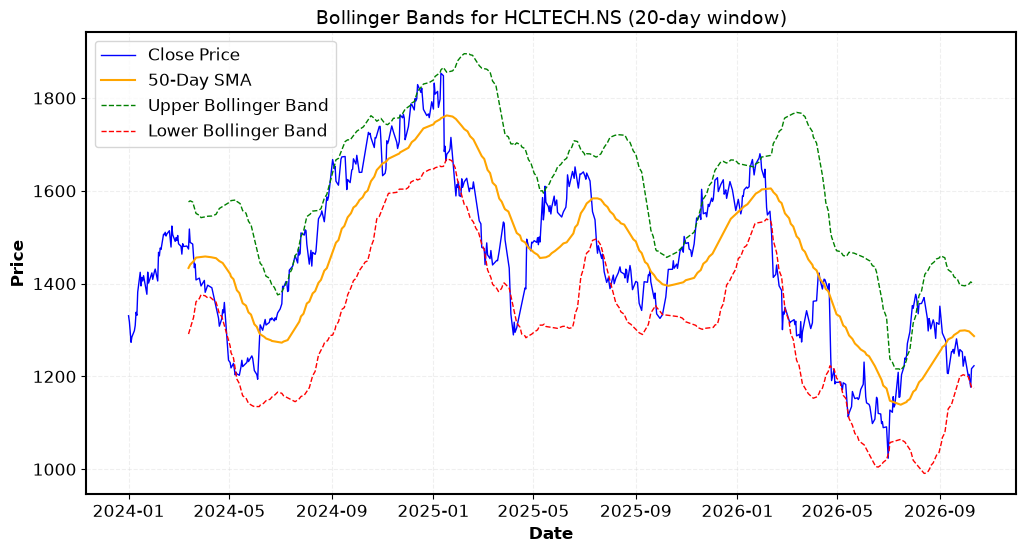

In [45]:
# Plot the data
plt.figure(figsize=(12, 6))
plt.plot(data.index, data['Close'], label="Close Price", color="blue", linewidth=1)
plt.plot(data.index, data['SMA'], label=f"{sma_window_length}-Day SMA", color="orange", linewidth=1.5)
plt.plot(data.index, data['upper'], label="Upper Bollinger Band", color="green", linestyle="--", linewidth=1)
plt.plot(data.index, data['lower'], label="Lower Bollinger Band", color="red", linestyle="--", linewidth=1)

# Add labels and legend
plt.title(f"Bollinger Bands for {ticker} (20-day window)", fontsize=14)
plt.xlabel("Date", fontsize=12)
plt.ylabel("Price", fontsize=12)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [55]:
df = yf.download("SWIGGY.NS", start="2023-01-01")

[*********************100%***********************]  1 of 1 completed


### MACD

In [56]:
def MACD(df):
    df["EMA12"] = df["Close"].ewm(span=12, adjust=False).mean()
    df["EMA26"] = df["Close"].ewm(span=26, adjust=False).mean()
    df["MCAD"] = df.EMA12 - df.EMA26
    df["signal"] = df["MCAD"].ewm(span=9, adjust=False).mean()

In [57]:
MACD(df)

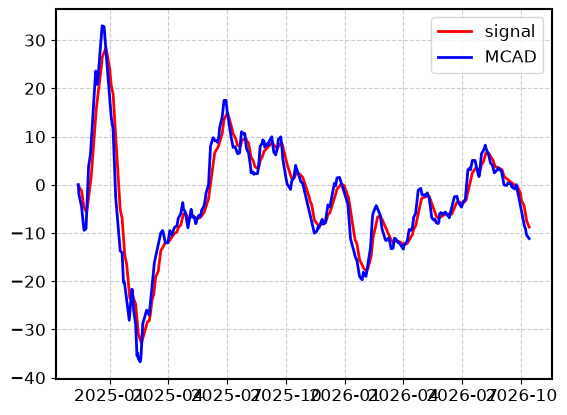

In [58]:
plt.plot(df.signal, label="signal", color="red")
plt.plot(df.MCAD, label="MCAD", color="blue")
plt.legend()
plt.show()

### Ichimoku Cloud Signal

In [239]:
ticker = "GRASIM.NS"
data = yf.Ticker(ticker).history(start="2026-01-10", end="2026-10-12")
df = pd.DataFrame(data).dropna()
df.reset_index(inplace=True)

In [240]:
df["ConversationLine"] = (df["Close"].rolling(
    window=9).max() + df["Close"].rolling(
    window=9).min()) / 2    #A
df["BaseLine"] = (df["Close"].rolling(
    window=26).max() + df["Close"].rolling(window=26).min()) / 2    #A
df["SpanA"] = ((df["ConversationLine"]
                + df["BaseLine"]) / 2).shift(26)
df["SpanB"] = ((df["Close"].rolling(
                window=52).max() + df["Close"].rolling(
                window=52).min()) / 2).shift(26)    #A
df["LaggingSpan"] = df["Close"].shift(-26)    #A

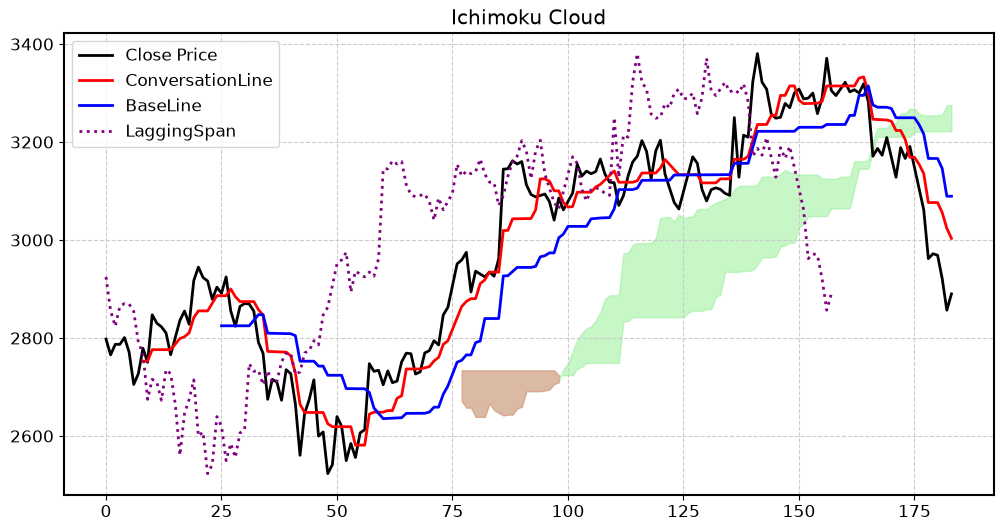

In [241]:
plt.figure(figsize=(12, 6))
plt.plot(df.index, df["Close"], label="Close Price", color="black")
plt.plot(df.index, df["ConversationLine"], label="ConversationLine", color="red")
plt.plot(df.index, df["BaseLine"], label="BaseLine", color="blue")
plt.fill_between(df.index, df["SpanA"], df["SpanB"], where=df["SpanA"] >= df["SpanA"], color="lightgreen", alpha=0.5)
plt.fill_between(df.index, df["SpanA"], df["SpanB"], where=df["SpanA"] < df["SpanB"], color="lightcoral", alpha=0.5)
plt.plot(df.index, df["LaggingSpan"], label="LaggingSpan", color="purple", linestyle="dotted")

plt.title("Ichimoku Cloud")
plt.legend()
plt.show()

In [243]:
ticker = "APOLLOHOSP.NS"
data = yf.Ticker(ticker).history(start="2020-01-01", end="2025-05-15")
df = pd.DataFrame(data).dropna()

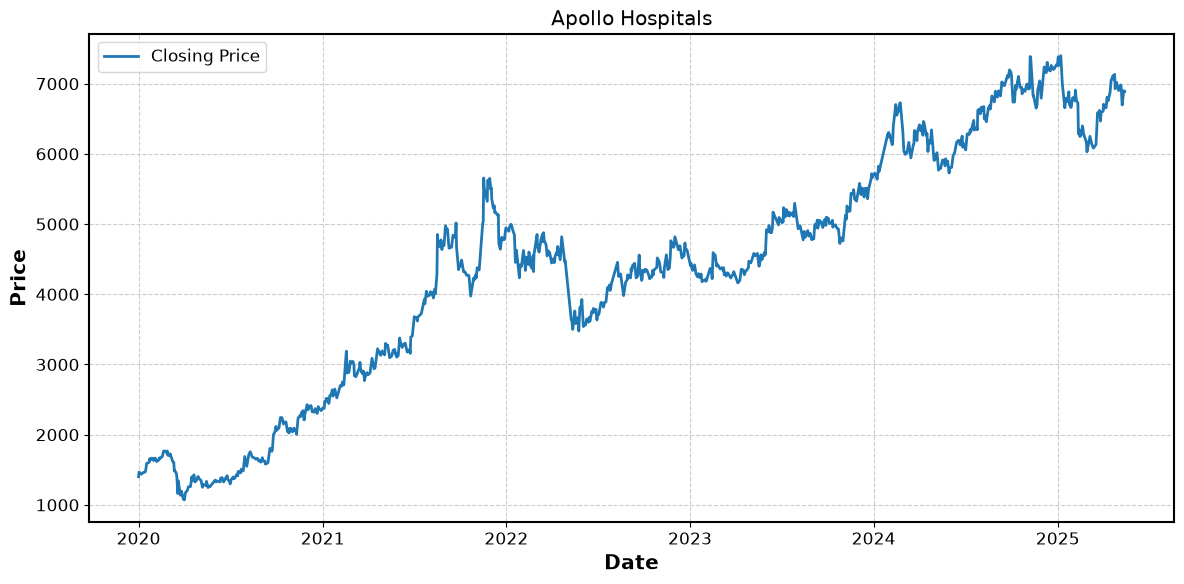

In [244]:
plt.figure(figsize=(12, 6))
plt.plot(df.index, df["Close"], label="Closing Price", linewidth=2)
plt.title("Apollo Hospitals")
plt.xlabel("Date")
plt.ylabel("Price")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [245]:
def plot(ticker, start, end):
    data = yf.Ticker(ticker).history(start=start, end=end, interval="1d")
    df = pd.DataFrame(data).dropna()
    plt.figure(figsize=(12, 6))
    plt.plot(df.index, df["Close"], label="Closing Price", linewidth=2)
    plt.title(ticker)
    plt.xlabel("Date")
    plt.ylabel("Price")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

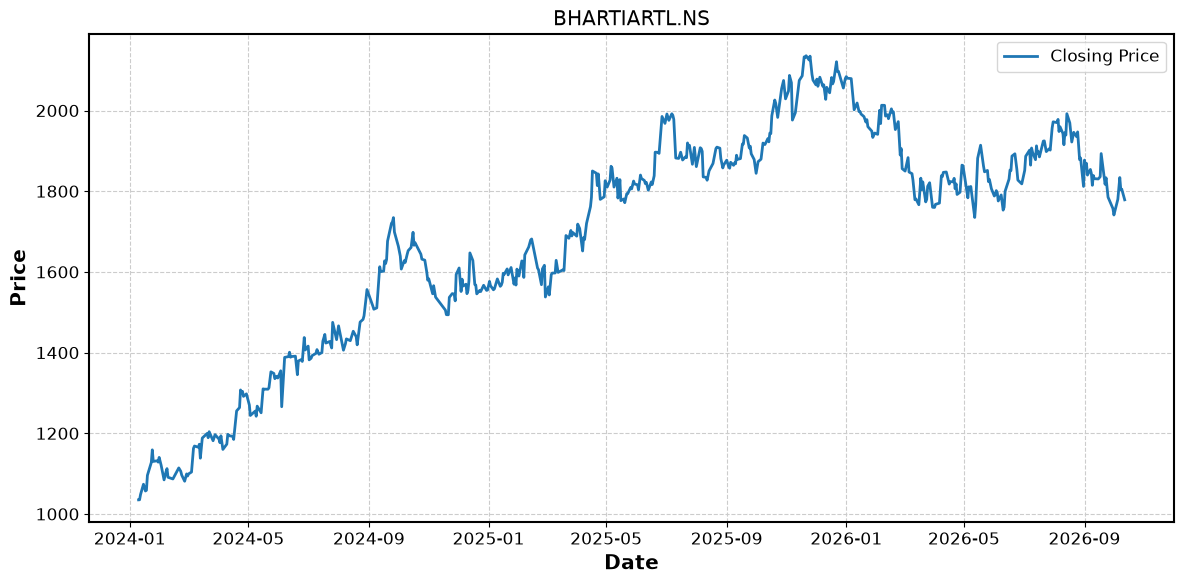

In [257]:
plot("BHARTIARTL.NS", "2024-01-10", "2026-10-13")

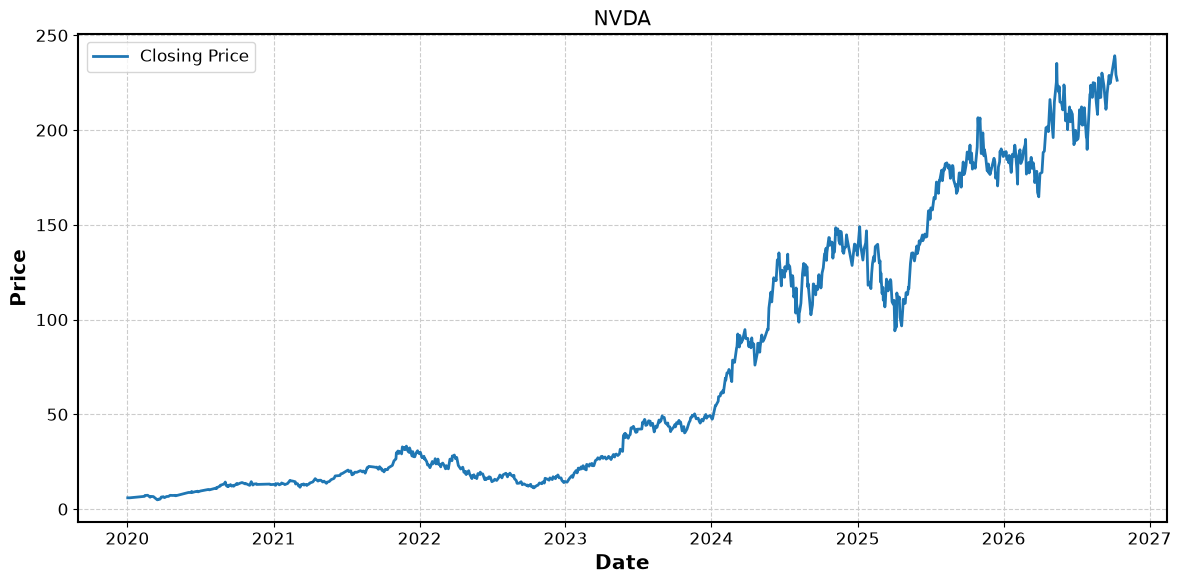

In [258]:
plot("NVDA", "2020-01-01", end="2026-10-13")

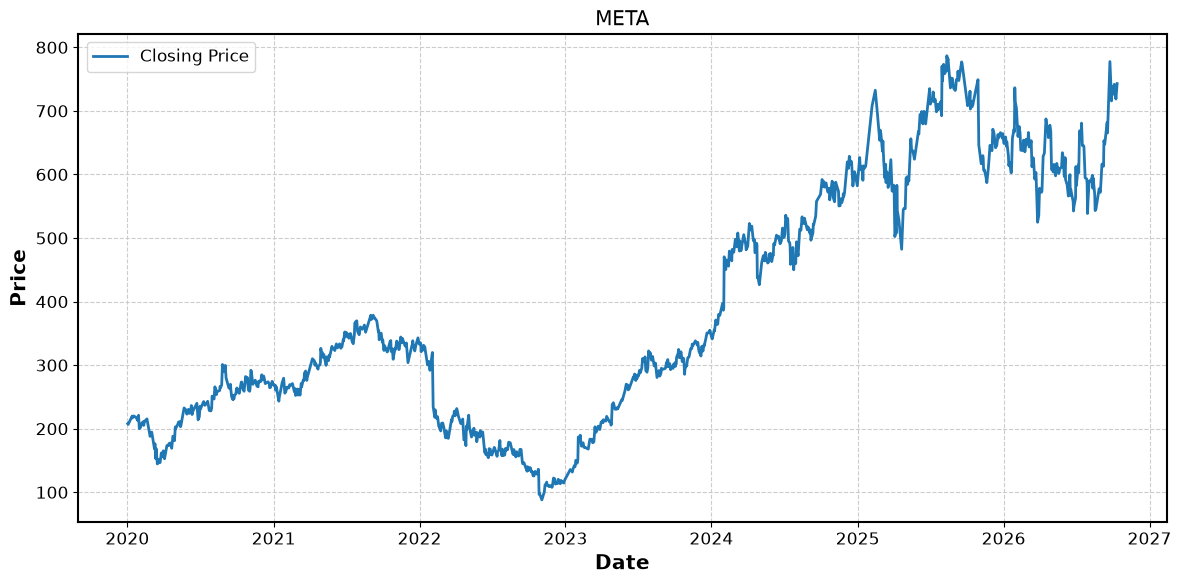

In [260]:
plot("META", "2020-01-01", end="2026-10-13")

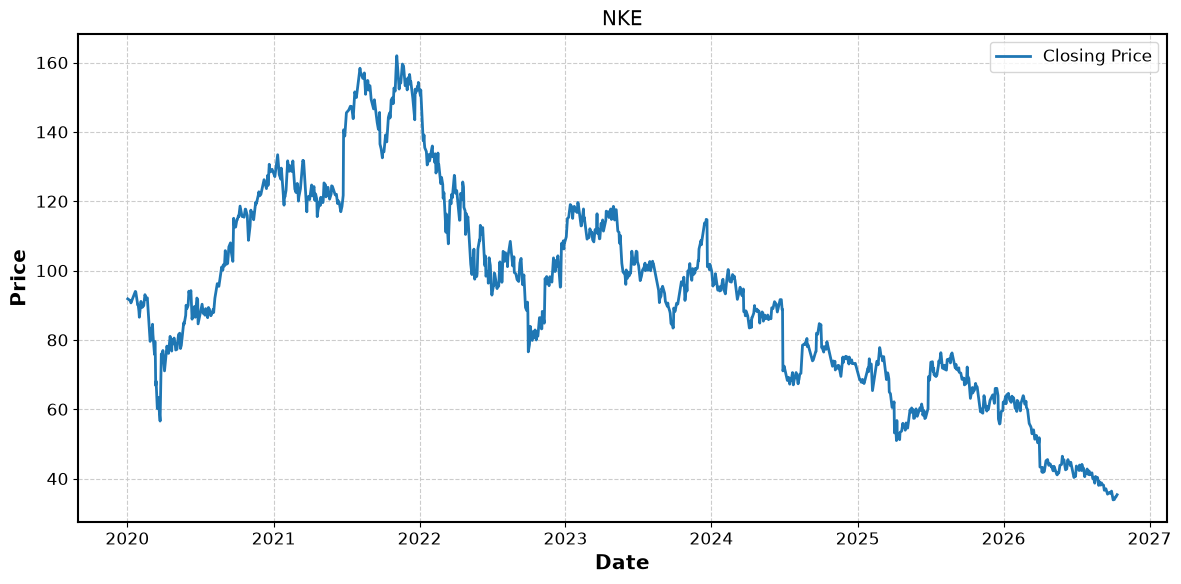

In [262]:
plot("NKE", "2020-01-01", end="2026-10-13")

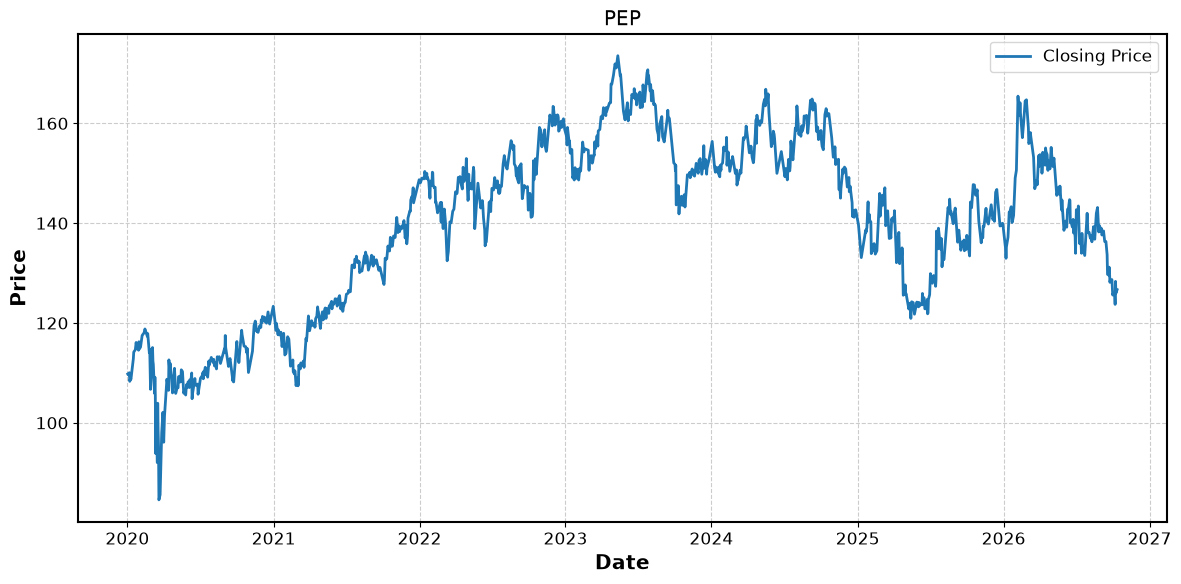

In [263]:
plot("PEP", "2020-01-01", end="2026-10-13")

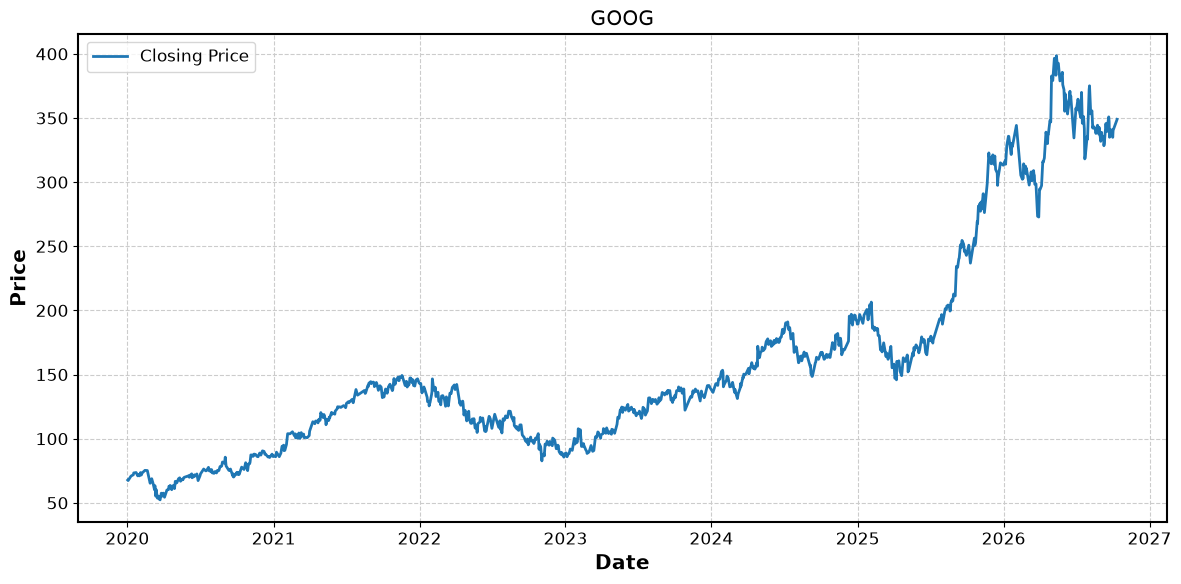

In [265]:
plot("GOOG", "2020-01-01", end="2026-10-13")

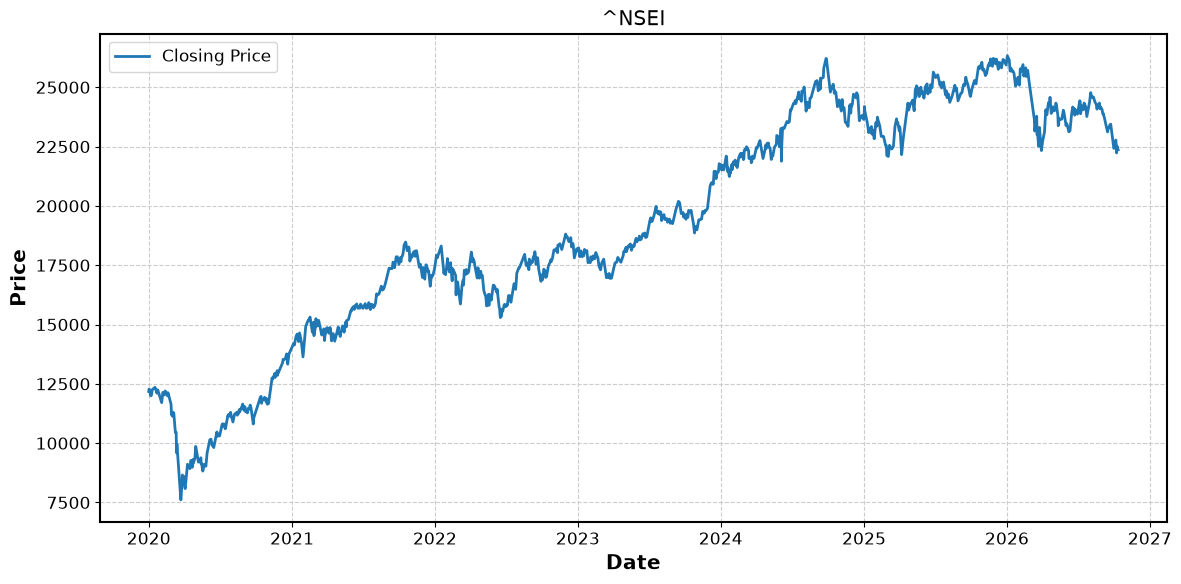

In [266]:
plot("^NSEI", "2020-01-01", end="2026-10-13")

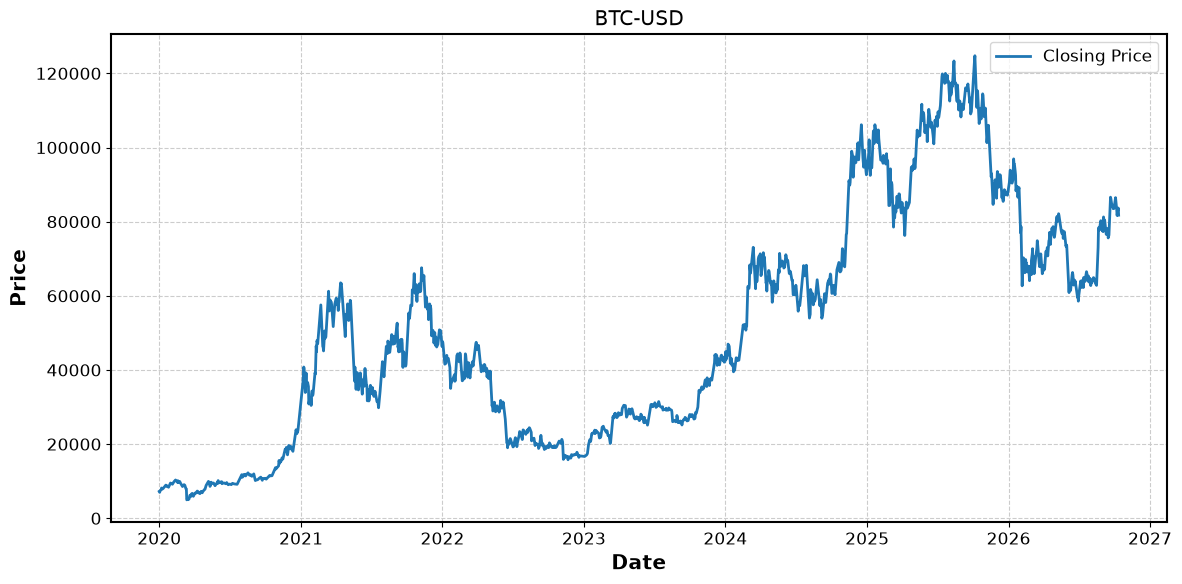

In [267]:
plot("BTC-USD", "2020-01-01", end="2026-10-13")

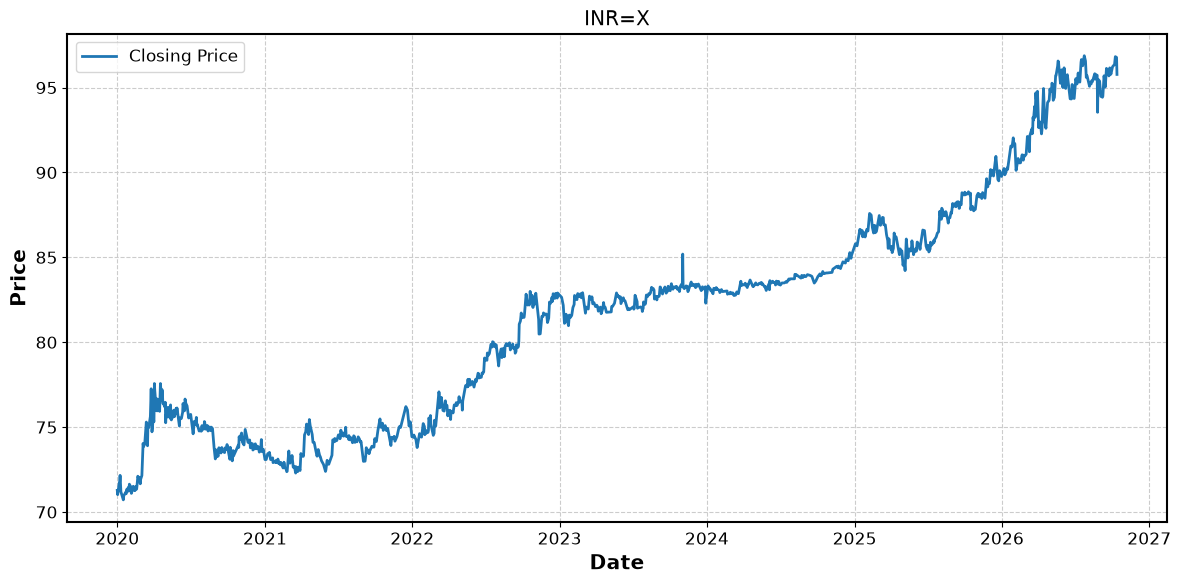

In [268]:
plot("INR=X", "2020-01-01", end="2026-10-13")

### Bollinger Bands

In [269]:
ticker = "ADANIENT.NS"
data = yf.Ticker(ticker).history(start="2024-01-01")

In [270]:
sma_window_length = 20
std_dev_factor = 2
data['SMA'] = data['Close'].rolling(window=sma_window_length).mean()
rolling_std = data['Close'].rolling(window=sma_window_length).std()
data['rf'] = (rolling_std * std_dev_factor)
data['upper'] =  data['SMA'] + data['rf']
data['lower'] =  data['SMA'] - data['rf']

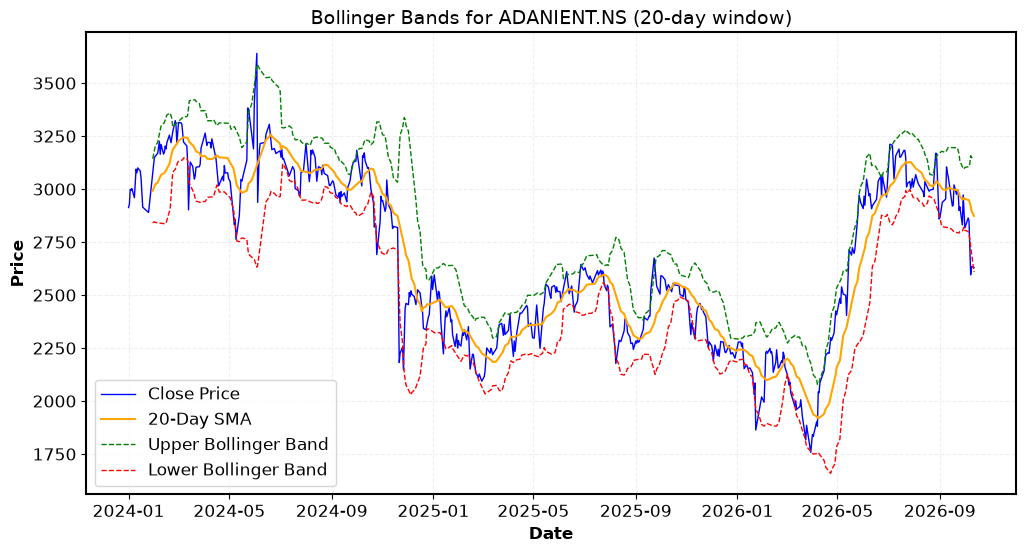

In [271]:
plt.figure(figsize=(12, 6))
plt.plot(data.index, data['Close'], label="Close Price", color="blue", linewidth=1)
plt.plot(data.index, data['SMA'], label=f"{sma_window_length}-Day SMA", color="orange", linewidth=1.5)
plt.plot(data.index, data['upper'], label="Upper Bollinger Band", color="green", linestyle="--", linewidth=1)
plt.plot(data.index, data['lower'], label="Lower Bollinger Band", color="red", linestyle="--", linewidth=1)

# Add labels and legend
plt.title(f"Bollinger Bands for {ticker} (20-day window)", fontsize=14)
plt.xlabel("Date", fontsize=12)
plt.ylabel("Price", fontsize=12)
plt.legend()
plt.grid(alpha=0.3)
plt.show()